# Data exploration and preparation

This notebook walks through the full data pipeline, from a dataset recipe to collated `NeuralBatch` tensors, and provides inline visualisations at every step.

**Sections**
1. Environment & imports
2. Dataset loading
3. Raw data structure
4. Batch collation
5. Signal augmentations

---
## 1. Environment & imports

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import sys
import re

# Run from repo root regardless of where the kernel was launched
REPO_ROOT = os.path.abspath(os.path.join(os.path.dirname('__file__'), '..'))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

# Load .envrc so dataset paths are available regardless of how Jupyter was launched.
# Keys already present in the environment are left untouched.

_envrc = os.path.join(REPO_ROOT, ".envrc")
if os.path.exists(_envrc):
    with open(_envrc) as _f:
        for _line in _f:
            _m = re.match(r'^export\s+(\w+)=(["\']?)(.+?)\2\s*$', _line.strip())
            if _m:
                _key, _val = _m.group(1), _m.group(3)
                if _key not in os.environ:
                    os.environ[_key] = _val
                    print(f"  set  {_key}")
                else:
                    print(f"  skip {_key}  (already in environment)")
else:
    print(f"WARNING: .envrc not found at {_envrc}")


import numpy as np
import torch
from IPython.display import display
from torch.utils.data import DataLoader
from transformers import WhisperTokenizer

from brainwhisperer.viz import load_theme

THEME = load_theme()

TOKENIZER = WhisperTokenizer.from_pretrained(
    'openai/whisper-tiny', language='en', task='transcribe'
)

print('torch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

---
## 2. Dataset loading

Each dataset has a recipe in `RECIPES` that builds its trials as a prepared dataset, one item per sentence. The study data is read from `NEURALSHED_DATA_ROOT`.

Tries **CARD** first, then **Willett**, then falls back to a synthetic batch if these datasets are not found or properly loaded, so every cell below still runs without real data.

In [ ]:
from brainwhisperer.data.collate import SingleRecipeCollator, default_ragged_collator
from brainwhisperer.data.recipes import RECIPES

BATCH_SIZE    = 8
MAX_LABEL_LEN = 448     # data.max_seq_len in brainwhisperer/config/base.yaml
SPLIT         = 'val'   # 'train' works too, but takes longer to build

ds     = None
recipe = None
loader = None

for dataset_name in ('card', 'willet'):
    try:
        recipe = RECIPES[dataset_name]
        build  = recipe.build_val_dataset if SPLIT == 'val' else recipe.build_train_dataset
        ds     = build(max_label_len=MAX_LABEL_LEN)
        loader = DataLoader(
            ds,
            batch_size = BATCH_SIZE,
            collate_fn = SingleRecipeCollator(dataset_name, recipe, default_ragged_collator()),
            shuffle    = True,
        )
        print(f'Loaded {dataset_name!r} ({SPLIT}) — {len(ds)} samples')
        break
    except Exception as exc:
        ds, recipe, loader = None, None, None
        print(f'{dataset_name}: {exc}')

if ds is None:
    print('No real dataset found — using synthetic fallback')

In [ ]:
# Quick dataset summary
if ds is not None:
    from brainwhisperer.data.collection import day_indices

    days     = np.asarray(day_indices(ds, dataset_name))    # day index of every trial
    n_days   = recipe.NUM_DAYS
    shapes   = [np.asarray(ds[i].data[recipe.NEURAL]).shape for i in range(len(ds))]  # (C, T)
    t_values = [shape[1] for shape in shapes]
    c_value  = shapes[0][0]

    print(f'Sentences  : {len(ds)}')
    print(f'Days       : {n_days} in the study, {len(np.unique(days))} in this split '
          f'(indices {days.min()} – {days.max()})')
    print(f'Channels C : {c_value}  (fill rule to 512: {recipe.CHANNEL_FILL!r})')
    print(f'T per sentence — min {min(t_values)}, median {int(np.median(t_values))}, max {max(t_values)}')
else:
    n_days = 20
    print('synthetic')

---
## 3. Raw data structure

Datasets contain neural recording of subject(s) attempting to speak in both prompted and unstructured conversational contexts. As such, the data is divided per sentences of varying length. Multiple sentences have been recorded for each day of the study. Each sentence has the neural data associated which is a matrix of shape `(C, T_sentence)`, where `C` is the number of recorded channels and `T_sentence` are the timesteps associated with the sentence. In a recipe dataset it is stored as `ds[i].data[recipe.NEURAL]`.

In [ ]:
# ── parameters ────────────────────────────────────────────────────────────────
DAY_TO_SHOW    = None   # which day to visualise (None = first day in this split)
N_SENTENCES    = 10      # how many sentences to include in the stack
ZOOM_SENTENCE  = 0      # which sentence to zoom into (0 = front card)
ZOOM_CHANNELS  = (0, 16)    # channel range for the zoom box
ZOOM_TIME      = (0, 150)   # time frame range for the zoom box
# ──────────────────────────────────────────────────────────────────────────────

if ds is not None:
    from brainwhisperer.viz.data_pipeline import plot_dataset_structure

    with THEME:
        fig = plot_dataset_structure(
            ds,
            dataset_name,
            day           = int(days.min()) if DAY_TO_SHOW is None else DAY_TO_SHOW,
            n_sentences   = N_SENTENCES,
            zoom_sentence = ZOOM_SENTENCE,
            zoom_channels = ZOOM_CHANNELS,
            zoom_time     = ZOOM_TIME,
        )
    display(fig)
else:
    print('Skipped — no real dataset available')

---
## 4. Batch collation

`SingleRecipeCollator` receives a list of sentences forming a batch. It pads all sentences using the longest timespan (`T_max = max(T_i)`), producing a `NeuralBatch` of shape `(B, C, T_max)`. \
The ground truth sentence labels (Whisper token ids, padded with `-100`) and the phoneme targets are collected within the `NeuralBatch` too.

As "metadata", `NeuralBatch` classes contain and keep track of the original length, day and dataset name of all sentences forming the batch.

In [ ]:
from brainwhisperer.data.batch import NeuralBatch

if loader is not None:
    batch = next(iter(loader))
else:
    # Synthetic fallback — varied lengths so padding is visible
    B, C, T_max_synth = 8, 512, 3000
    synth_lengths = torch.randint(800, T_max_synth, (B,))
    synth_signals = torch.zeros(B, C, T_max_synth)
    for i, L in enumerate(synth_lengths):
        synth_signals[i, :, :L] = torch.randn(C, L.item())
    batch = NeuralBatch(
        signals  = synth_signals,
        labels   = torch.randint(0, 200, (B, 10)),
        datasets = ['synthetic'] * B,
        day_idx  = torch.randint(0, 20, (B,)),
        lengths  = synth_lengths,
    )

print('signals  :', tuple(batch.signals.shape), batch.signals.dtype)
print('labels   :', tuple(batch.labels.shape))
print('datasets :', batch.datasets)
print('day_idx  :', batch.day_idx.tolist())
print('lengths  :', batch.lengths.tolist())

# ── parameters ────────────────────────────────────────────────────────────────
MAX_ROWS = 8   # how many sentences to draw (top N of the batch)
# ──────────────────────────────────────────────────────────────────────────────

from brainwhisperer.viz.data_pipeline import plot_batch_anatomy

with THEME:
    fig = plot_batch_anatomy(batch, max_rows=MAX_ROWS)
display(fig)

---
## 5. Signal augmentations

Side-by-side comparison of a raw signal and its augmented version. Note that augmentation is applied during training, here we call `transform_data` directly to show its effect.

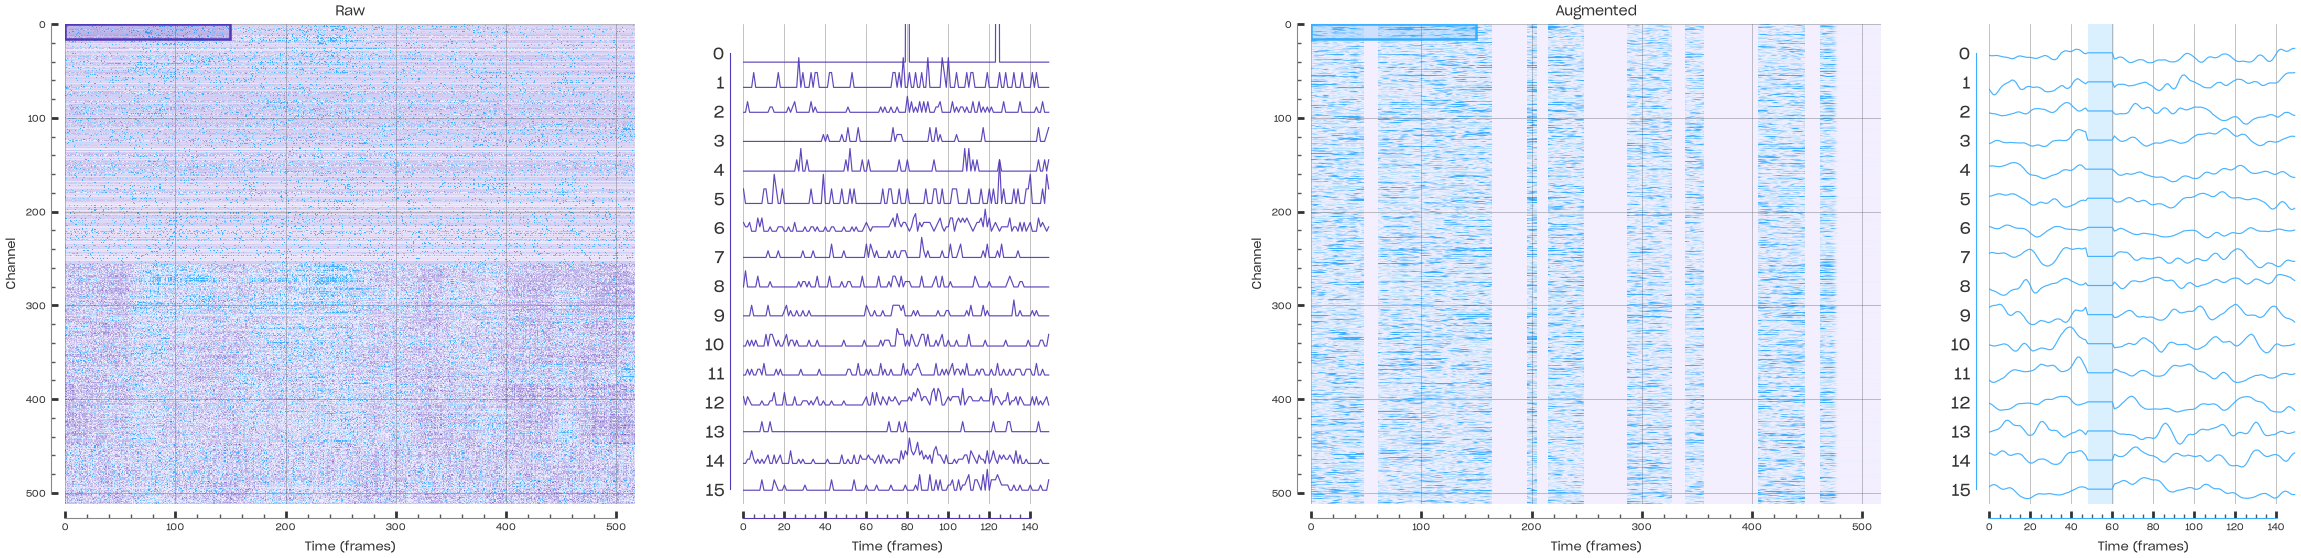

In [8]:
# ── parameters ────────────────────────────────────────────────────────────────
AUG_SAMPLE_IDX = 0          # which batch item to visualise
ZOOM_CHANNELS  = (0, 16)    # channel range for the zoom box
ZOOM_TIME      = (0, 150)   # time frame range for the zoom box
# ──────────────────────────────────────────────────────────────────────────────

from brainwhisperer.data.augmentations import transform_data
from brainwhisperer.viz.augmentations import plot_augmentation

raw          = batch.signals.clone()
augmented, _ = transform_data(batch.signals.clone(), batch.lengths.clone(), mode='train')

with THEME:
    fig = plot_augmentation(
        raw, augmented, batch.lengths,
        sample_idx    = AUG_SAMPLE_IDX,
        zoom_channels = ZOOM_CHANNELS,
        zoom_time     = ZOOM_TIME,
    )
display(fig)